# KCI 실험과 예산 역산 실험 비교

* KCI 방식: 질의를 한 번씩 추가하고, 상대폭 조건이 `streak`회 연속 만족되면 즉시 중단
* 역산 방식: 현재 총예산으로 허용되는 `k`회 질의를 한 라운드에서 수행하고, 각 라운드 내에서 `streak`회 연속으로 조건을 만족하면 `k`회 질의 이전에 조기 종료. 실패하면 총예산에 `step`을 곱해 새 라운드를 처음부터 수행
* 각 시행에서 실제 데이터 평균을 CI가 포함하는지(`covered`)를 모든 질의 시점에 저장


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ALPHA = 0.05    # 95% 신뢰구간
MAXQ = 500      # 루프 내 최대 쿼리 수

# ===현재 노트북 환경에 맞게 수정===
DATASETS = {
    "CardBase": {"path": Path("data/CardBase.csv"), "column": "Credit_Limit"},
    "Bank": {"path": Path("data/bank_exp.parquet"), "column": "credit_limit"},
}

# ===드라이브 전용===
# DATASETS = {
#     "CardBase": {"path": Path("/content/CardBase.csv"), "column": "Credit_Limit"},
#     "Bank": {"path": Path("/content/bank_exp.parquet"), "column": "credit_limit"},
# }

OUTPUT_DIR = Path("/content/outputs/result_single")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

> 시각화 정의
* `plt.rcParams.update`

In [2]:
# @title
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
})

> 데이터셋 로드
* `load_dataset()`

In [3]:
# @title
def load_dataset(path, column):
    path = Path(path)
    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path)
    elif path.suffix.lower() == ".parquet":
        df = pd.read_parquet(path)
    else:
        raise ValueError(f"지원하지 않는 파일 형식: {path}")
    if column not in df.columns:
        raise KeyError(f"{path}에 {column!r} 열이 없습니다.")
    x = pd.to_numeric(df[column], errors="coerce").dropna().to_numpy(float)
    if len(x) == 0:
        raise ValueError(f"{path}의 {column!r} 열에 유효한 숫자가 없습니다.")
    n = len(x)
    return {
        "x": x,
        "n": n,
        "true_mean": float(x.mean()),
        "min": float(x.min()),
        "max": float(x.max()),
        "delta": float((x.max() - x.min()) / n),
    }

### 원본 데이터셋 통계 정보

In [4]:
DATA = {name: load_dataset(cfg["path"], cfg["column"])
        for name, cfg in DATASETS.items()}

# ===통계 정보를 DataFrame으로 변환===
pd.DataFrame([
    {"dataset": name, **{k: v for k, v in d.items() if k != "x"}}
    for name, d in DATA.items()
])

,dataset,n,true_mean,min,max,delta
0,CardBase,500,252614.000000,2000.0,899000.0,1794.000000
1,Bank,6744,9074.479537,1439.0,34516.0,4.904656


> 유틸리티 함수 정의
* `_statistics`: 현재까지의 응답값으로 누적 통계와 95% CI를 계산
* `_final_from_history`: ...
* `_validate_inputs`: 인풋값 유효성 검증

In [5]:
# @title
def _statistics(values, true_mean, alpha=ALPHA):
    """현재까지의 응답값으로 누적 통계와 95% CI를 계산한다."""
    values = np.asarray(values, dtype=float)


    # 응답 값 개수로 k를 계산함
    k = len(values)
    cumulative_mean = float(values.mean())

    if k < 2:
        return {
            "k": k, "response": float(values[-1]),
            "cumulative_mean": cumulative_mean,
            "sample_std": np.nan, "standard_error": np.nan,
            "moe": np.nan, "ci_lo": np.nan, "ci_hi": np.nan,
            "ci_width": np.nan, "relative_width": np.nan,
            "hit": False, "covered": pd.NA,
        }

    sample_std = float(values.std(ddof=1))
    standard_error = sample_std / np.sqrt(k)
    t_value = stats.t.ppf(1 - alpha / 2, df=k - 1)
    moe = float(t_value * standard_error)
    ci_lo = cumulative_mean - moe
    ci_hi = cumulative_mean + moe
    ci_width = float(2 * moe)
    relative_width = float(ci_width / abs(cumulative_mean)) if cumulative_mean != 0 else np.inf
    covered = bool(ci_lo <= true_mean <= ci_hi)

    return {
        "k": k, "response": float(values[-1]),
        "cumulative_mean": cumulative_mean,
        "sample_std": sample_std, "standard_error": standard_error,
        "moe": moe, "ci_lo": ci_lo, "ci_hi": ci_hi,
        "ci_width": ci_width, "relative_width": relative_width,
        "hit": False, "covered": covered,
    }

def _final_from_history(history, **metadata):
    # 히스토리 데이터에서 마지막 행을 꺼내서, 메타데이터를 덧붙여 반환
    row = history.iloc[-1].to_dict()
    row.update(metadata)
    return row

def _validate_inputs(eps, threshold, streak_required, maxq):
    if eps <= 0:
        raise ValueError("eps는 0보다 커야 합니다.")
    if threshold <= 0:
        raise ValueError("threshold는 0보다 커야 합니다.")
    if streak_required < 1:
        raise ValueError("streak_required는 1 이상이어야 합니다.")
    if maxq < 2:
        raise ValueError("maxq는 2 이상이어야 합니다.")

> 오버랩 시각화를 위한 함수 추가

In [6]:
# @title
def _overlap_from_ci(ci_lo, ci_hi, delta):
    """원본 CI를 -delta만큼 이동한 가상 인접 CI와 비교한다."""
    if not (np.isfinite(ci_lo) and np.isfinite(ci_hi)):
        return {"adj_ci_lo": np.nan, "adj_ci_hi": np.nan,
                "overlap_width": np.nan, "overlap_ratio": np.nan,
                "width_to_delta": np.nan}
    adj_ci_lo = ci_lo - delta
    adj_ci_hi = ci_hi - delta
    overlap_width = max(0.0, min(ci_hi, adj_ci_hi) - max(ci_lo, adj_ci_lo))
    ci_width = ci_hi - ci_lo
    return {
        "adj_ci_lo": adj_ci_lo,
        "adj_ci_hi": adj_ci_hi,
        "overlap_width": overlap_width,
        "overlap_ratio": overlap_width / ci_width if ci_width > 0 else np.nan,
        "width_to_delta": ci_width / delta if delta > 0 else np.nan,
    }

> kci 방식 단독 실험 함수
* `run_kci_live()`

In [7]:
# @title
def run_kci_live(data, eps, threshold, streak_required, maxq=MAXQ,
                  seed=0, alpha=ALPHA, verbose=False):
    """KCI 방식의 단일 시행.

    질의를 순차적으로 수행하고 상대폭이 threshold 미만인 상태가
    streak_required회 연속이면 그 시점에서 중단한다.
    반환: (전체 질의 궤적 DataFrame, 최종 결과 dict)
    """
    _validate_inputs(eps, threshold, streak_required, maxq)
    rng = np.random.default_rng(seed)
    scale = data["delta"] / eps
    responses = []
    rows = []
    streak_count = 0
    stopped = False

    for k in range(1, maxq + 1):
        response = float(data["true_mean"] + rng.laplace(0.0, scale))
        responses.append(response)
        row = _statistics(responses, data["true_mean"], alpha)

        # ===오버랩 지표 찍기 위해 추가===
        row.update(_overlap_from_ci(row["ci_lo"], row["ci_hi"], data["delta"]))

        hit = bool(np.isfinite(row["relative_width"]) and row["relative_width"] < threshold)
        streak_count = streak_count + 1 if hit else 0
        row.update({"threshold": threshold, "hit": hit, "streak_count": streak_count})
        rows.append(row)

        if verbose:
            print(f"k={k:4d} | response={response:,.3f} | mean={row['cumulative_mean']:,.3f} | "
                  f"width={row['ci_width'] if np.isfinite(row['ci_width']) else np.nan:,.3f} | "
                  f"relw={row['relative_width'] if np.isfinite(row['relative_width']) else np.nan:.6f} | "
                  f"hit={hit} | streak={streak_count}")

        if streak_count >= streak_required:
            stopped = True
            break

    history = pd.DataFrame(rows)
    final = _final_from_history(
        history,
        method="KCI",
        eps=float(eps),
        eps_total=float(eps * len(history)),
        threshold=float(threshold),
        streak_required=int(streak_required),
        seed=int(seed),
        delta=float(data["delta"]),
        laplace_scale=float(scale),
        true_mean=float(data["true_mean"]),
        k_stop=int(len(history)),
        converged=bool(stopped),
    )
    if not stopped:
        raise RuntimeError(f"KCI가 maxq={maxq}회 안에 수렴하지 않았습니다.")
    return history, final

> kci 방식 시각화 함수
* `plot_kci_live()`

In [8]:
# @title
def plot_kci_live(history, final, title=None, save=None):
    """KCI 단일 시행의 누적 평균·CI·상대폭·coverage + 수렴점 오버랩 시각화."""
    fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(12, 11.5), constrained_layout=True,
                                        gridspec_kw={"height_ratios": [1.35, 1, 1.05]})
    h = history.copy()
    valid = h["k"] >= 2
    stable = h["hit"] == True
    blue, red, green, gray = "#2166AC", "#D55E4A", "#1A9850", "#666666"
    orange, purple = "#d6604d", "#762A83"

    # ── 패널 1: 수렴 궤적 (기존과 동일) ──
    ax0.scatter(h["k"], h["response"], s=18, color=gray, alpha=.55, label="Noisy response")
    ax0.plot(h["k"], h["cumulative_mean"], color=blue, lw=1.8, label="Cumulative mean")
    ax0.fill_between(h.loc[valid, "k"].to_numpy(), h.loc[valid, "ci_lo"].to_numpy(),
                     h.loc[valid, "ci_hi"].to_numpy(), color=blue, alpha=.13, label="95% CI")
    ax0.scatter(h.loc[valid & stable, "k"], h.loc[valid & stable, "cumulative_mean"],
                s=24, color=red, zorder=4, label="Threshold hit")
    ax0.axhline(final["true_mean"], color=green, ls="--", lw=1.4, label="True mean")
    ax0.axvline(final["k_stop"], color="black", ls=":", lw=1.3, label=f"Stop k={final['k_stop']}")
    ax0.set_title(title or "KCI single-run trajectory")
    ax0.set_xlabel("Query count k"); ax0.set_ylabel("Query output")
    ax0.legend(frameon=False, ncol=5, loc="best")

    # ── 패널 2: 상대폭 (기존과 동일) ──
    ax1.plot(h["k"], h["relative_width"], color=blue, lw=1.8, label="Relative width")
    ax1.axhline(final["threshold"], color=red, ls="--", lw=1.3, label="Threshold")
    ax1.scatter(h.loc[valid & stable, "k"], h.loc[valid & stable, "relative_width"],
                color=red, s=24, zorder=3)
    ax1.axvline(final["k_stop"], color="black", ls=":", lw=1.3)
    ax1.set_xlabel("Query count k"); ax1.set_ylabel("Relative CI width")
    ax1.set_title(f"Relative-width stopping rule | eps_total={final['eps_total']:.3f}")
    ax1.legend(frameon=False)
    ax1.text(.99, .98,
             f"covered at stop = {bool(final['covered'])}\n"
             f"absolute width = {final['ci_width']:,.3f}",
             transform=ax1.transAxes, ha="right", va="top",
             bbox=dict(boxstyle="round,pad=.35", facecolor="white", edgecolor="#aaa"))

    # ── 패널 3 (신규): 수렴점 원본/인접 CI 겹침 ──
    _plot_stop_overlap(ax2, history, final)
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

> 반복 실험을 위한 유틸리티 함수
* `_summarize_repeated()`: 반복 시행 최종 결과의 평균·중앙값·최소–최대·표준편차 요약

In [9]:
# @title
def _summarize_repeated(final_results, prefix=""):
    """반복 시행 최종 결과의 평균·중앙값·최소–최대·표준편차 요약."""
    metrics = ["k_stop", "eps_total", "ci_width", "relative_width", "covered"]
    row = {"n_reps": len(final_results)}
    for metric in metrics:
        if metric not in final_results.columns:
            continue
        values = final_results[metric].astype(float).to_numpy()
        row[f"{prefix}{metric}_mean"] = np.nanmean(values)
        row[f"{prefix}{metric}_median"] = np.nanmedian(values)
        row[f"{prefix}{metric}_min"] = np.nanmin(values)
        row[f"{prefix}{metric}_max"] = np.nanmax(values)
        row[f"{prefix}{metric}_std"] = np.nanstd(values, ddof=1) if len(values) > 1 else np.nan
    return pd.DataFrame([row])

> 역산 방식 전용 오버랩 시각화 함수
* `_plot_stop_overlap()`

In [10]:
# @title
def _plot_stop_overlap(ax, history, final, blue="#2166AC", orange="#d6604d",
                       green="#1A9850", purple="#762A83", gray="#666666"):
    """수렴 시점의 원본 CI와 Δ 이동 인접 CI의 겹침을 수평 interval plot으로 그린다.

    KCI(final에 eps_total)와 INVERSE(final에 actual_eps_total)를 모두 지원.
    """
    delta = float(final["delta"])
    shift = -delta                       # 인접 DB 방향: 최대값 레코드 제거
    mean = float(final["cumulative_mean"])
    ci_lo, ci_hi = float(final["ci_lo"]), float(final["ci_hi"])
    adj_center, adj_lo, adj_hi = mean + shift, ci_lo + shift, ci_hi + shift
    ov_lo, ov_hi = max(ci_lo, adj_lo), min(ci_hi, adj_hi)
    ov_w = max(0.0, ov_hi - ov_lo)
    ov_ratio = ov_w / (ci_hi - ci_lo) if ci_hi > ci_lo else np.nan
    eps_label = final.get("eps_total", final.get("actual_eps_total"))

    y_resp = .02 * np.sin(np.arange(len(history)) * 2.4)
    ax.scatter(history["response"], y_resp, s=28, color=gray, alpha=.7, zorder=3)
    ax.axvline(final["true_mean"], color=green, ls="--", lw=1.5, label="True mean")
    ax.plot([ci_lo, ci_hi], [.62, .62], color=blue, lw=8, solid_capstyle="round",
            label="Original 95% CI")
    ax.plot([adj_lo, adj_hi], [.35, .35], color=orange, lw=8, solid_capstyle="round",
            label="Shifted adjacent 95% CI")
    if ov_w > 0:
        ax.plot([ov_lo, ov_hi], [.485, .485], color=purple, lw=10,
                solid_capstyle="round", label="CI overlap")
    ax.axvline(mean, color=blue, lw=1.2, alpha=.85)
    ax.axvline(adj_center, color=orange, lw=1.2, alpha=.85)
    mid = (mean + adj_center) / 2
    ax.annotate("", xy=(adj_center, .86), xytext=(mean, .86),
                arrowprops=dict(arrowstyle="<->", color="black", lw=1.2))
    ax.text(mid, .89, f"Δ={delta:,.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_yticks([0, .35, .485, .62, .86])
    ax.set_yticklabels(["Responses", "Adjacent CI", "Overlap", "Original CI", "Centers"])
    ax.set_xlabel("Query output")
    ax.set_title("Stopping-point interval comparison")
    ax.set_ylim(-.12, 1.02)
    ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.22), frameon=False)
    ax.text(1.0, 1.02,
            f"k_stop={final['k_stop']} | ε_total={eps_label:.2f}\n"
            f"width={final['ci_width']:,.1f} | relw={final['relative_width']:.4f}\n"
            f"overlap ratio={ov_ratio:.3f} | width/Δ={final['ci_width']/delta:.3f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
            bbox=dict(boxstyle="round,pad=.35", facecolor="white", edgecolor="#bbbbbb"))

> 역산 방식 시각화 함수
* `plot_inverse_live()`

In [11]:
# @title
def plot_inverse_live(round_summary, trajectory, final, title=None, save=None):
    """역산 단일 시행의 예산 라운드와 성공 라운드 내부 궤적 + 수렴점 오버랩 시각화."""
    fig = plt.figure(figsize=(13, 12), constrained_layout=True)
    gs = fig.add_gridspec(3, 2, height_ratios=[1.0, 1.0, 1.05])
    ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1])
    ax2 = fig.add_subplot(gs[1, 0]); ax3 = fig.add_subplot(gs[1, 1])
    ax4 = fig.add_subplot(gs[2, :])
    blue, red, green, gray, purple = "#2166AC", "#D55E4A", "#1A9850", "#666666", "#762A83"

    rs = round_summary
    ax0.plot(rs["round"], rs["candidate_eps_total"], "o-", color=blue, lw=1.8)
    success_rows = rs[rs["round_success"] == True]
    if len(success_rows):
        ax0.scatter(success_rows["round"], success_rows["candidate_eps_total"], color=green, s=70, zorder=4, label="Success")
    ax0.set_title("Candidate budget by round"); ax0.set_xlabel("Round"); ax0.set_ylabel("Candidate total epsilon")
    ax0.legend(frameon=False) if len(success_rows) else None

    ax1.plot(rs["round"], rs["k_max"], "o-", color=purple, lw=1.8, label="k_max")
    ax1.scatter(rs["round"], rs["k_stop"], color=green, s=45, zorder=3, label="k_stop")
    ax1.axvline(final["round"], color="black", ls=":", lw=1.3)
    ax1.set_title("Allowed and actual stopping query counts"); ax1.set_xlabel("Round"); ax1.set_ylabel("Query count")
    ax1.legend(frameon=False, fontsize=8)

    success_round = int(final["round"])
    h = trajectory[trajectory["round"] == success_round].copy()
    valid = h["k"] >= 2
    ax2.scatter(h["k"], h["response"], color=gray, s=18, alpha=.55, label="Noisy response")
    ax2.plot(h["k"], h["cumulative_mean"], color=blue, lw=1.8, label="Cumulative mean")
    ax2.fill_between(h.loc[valid, "k"].to_numpy(), h.loc[valid, "ci_lo"].to_numpy(),
                     h.loc[valid, "ci_hi"].to_numpy(), color=blue, alpha=.13, label="95% CI")
    ax2.axhline(final["true_mean"], color=green, ls="--", label="True mean")
    ax2.set_title(f"Successful round trajectory (round={success_round}, k={final['k']})")
    ax2.set_xlabel("Within-round query count k"); ax2.set_ylabel("Query output")
    ax2.legend(frameon=False, fontsize=8)

    ax3.plot(h["k"], h["relative_width"], color=blue, lw=1.8, label="Relative width")
    ax3.axhline(final["threshold"], color=red, ls="--", label="Threshold")
    tail = h.tail(final["streak_required"])
    if len(tail):
        ax3.scatter(tail["k"], tail["relative_width"], color=red, s=35, zorder=3,
                    label=f"Last {final['streak_required']} checks")
    ax3.set_title(f"Final round check | actual eps={final['actual_eps_total']:.3f}")
    ax3.set_xlabel("Within-round query count k"); ax3.set_ylabel("Relative CI width")
    ax3.legend(frameon=False, fontsize=8)

    # ── 하단 전체폭 패널 (신규): 성공(마지막) 시행의 원본/인접 CI 겹침 ──
    _plot_stop_overlap(ax4, h, final)
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

> 예산 역산 방식 단독 실행 함수
* `run_inverse_live()`

In [12]:
# @title
def run_inverse_live(data, eps, threshold, streak_required,
                      initial_eps_total, step, max_rounds=20,
                      maxq=MAXQ, seed=0, alpha=ALPHA, verbose=False):
    """예산 역산 방식의 단일 시행.

    각 라운드에서 k=floor(eps_total/eps)회 질의를 새로 수행한다.
    마지막 streak개 상대폭이 모두 threshold 미만이면 성공하고,
    아니면 eps_total을 step배로 늘려 다음 라운드를 처음부터 수행한다.
    반환: (라운드 요약, 라운드 내부 전체 궤적, 최종 결과)
    """
    _validate_inputs(eps, threshold, streak_required, maxq)
    if initial_eps_total <= 0:
        raise ValueError("initial_eps_total은 0보다 커야 합니다.")
    if step <= 1:
        raise ValueError("step은 1보다 커야 합니다.")
    if max_rounds < 1:
        raise ValueError("max_rounds는 1 이상이어야 합니다.")

    round_summaries = []
    trajectory_frames = []
    eps_total = float(initial_eps_total)
    success = False
    final_result = None

    for round_no in range(1, max_rounds + 1):
        candidate_eps_total = float(eps_total)

        # 정수형 몫을 가지고 질의 횟수 k를 잡기 때문에 엡실론 분포가 이산적임
        k_max = int(candidate_eps_total // eps)
        if k_max < 2:
            round_summaries.append({
                "round": round_no, "candidate_eps_total": candidate_eps_total,
                "k_max": k_max, "k_stop": np.nan,
                "actual_eps_total": np.nan,
                "round_success": False, "final_mean": np.nan,
                "final_ci_width": np.nan, "final_relative_width": np.nan,
                "final_covered": pd.NA, "streak_pass": False,
            })
            eps_total *= step
            continue
        if k_max > maxq:
            raise ValueError(f"round={round_no}에서 k_max={k_max}가 maxq={maxq}를 초과합니다.")


        # 라운드마다 새로운 난수 생성 stream을 사용. round_no와 seed를 분리해 기록
        round_seed = int(seed + round_no * 1_000_003) # 소수로 곱해 seed를 섞음

        # 난수 생성 제너레이터 rng
        rng = np.random.default_rng(round_seed)


        # 민감도 / 엡실론 = 라플라스 분포의 스케일
        scale = data["delta"] / eps


        responses = []
        rows = []


        streak_count = 0
        stopped_k = None


        # 중첩 for문: 실제 라운드 내 질의 수행
        for local_k in range(1, k_max + 1):
            # responses = []는 숫자 값 리스트
            responses.append(float(data["true_mean"] + rng.laplace(0.0, scale)))


            # _statistics는 현재까지의 응답값으로 누적 통계와 95% CI를 계산
            row = _statistics(responses, data["true_mean"], alpha)


            # ===오버랩 지표 찍기 위해 추가===
            row.update(_overlap_from_ci(row["ci_lo"], row["ci_hi"], data["delta"]))


            # np.isfinite(row["relative_width"]) -> 값 유효성 검사
            # row["relative_width"] < threshold -> 상대폭이 threshold 미만인지 확인
            hit = bool(np.isfinite(row["relative_width"]) and row["relative_width"] < threshold)
            streak_count = streak_count + 1 if hit else 0


            # 딕셔너리에 새로운 키-값 쌍을 추가하거나, 이미 있는 키의 값을 바꿈
            row.update({"round": round_no, "candidate_eps_total": candidate_eps_total,
                        "k_max": k_max, "actual_eps_total": eps * local_k,
                        "threshold": threshold, "hit": hit,
                        "streak_count": streak_count,
                        "round_seed": round_seed})
            rows.append(row)
            if streak_count >= streak_required:
                stopped_k = local_k
                break       # for문 즉시 종료


        # 라운드 내의 모든 질의 반복 후, 해당 라운드의 궤적을 DataFrame으로 변환하고 기록
        trajectory = pd.DataFrame(rows)
        trajectory_frames.append(trajectory)
        round_success = stopped_k is not None
        streak_pass = round_success
        last = trajectory.iloc[-1]

        round_summaries.append({
            "round": round_no, "candidate_eps_total": candidate_eps_total,
            "k_max": k_max, "k_stop": int(stopped_k) if stopped_k is not None else np.nan,
            "actual_eps_total": float(eps * stopped_k) if stopped_k is not None else float(eps * k_max),
            "round_success": round_success,
            "final_mean": last["cumulative_mean"],
            "final_ci_width": last["ci_width"],
            "final_relative_width": last["relative_width"],
            "final_covered": last["covered"],
            "streak_pass": streak_pass,
            "round_seed": round_seed,
        })

        if verbose:
            print(f"round={round_no:3d} | candidate_eps_total={candidate_eps_total:.4f} | "
                  f"k_max={k_max:4d} | k_stop={stopped_k} | "
                  f"actual_eps_total={eps * (stopped_k if stopped_k is not None else k_max):.4f} | "
                  f"final_relw={last['relative_width']:.6f} | "
                  f"streak_pass={streak_pass}")

        if round_success:
            success = True
            final_result = _final_from_history(
                trajectory,
                method="INVERSE",
                eps=float(eps), candidate_eps_total=float(candidate_eps_total),
                actual_eps_total=float(eps * stopped_k),
                threshold=float(threshold), streak_required=int(streak_required),
                step=float(step), initial_eps_total=float(initial_eps_total),
                seed=int(seed), round_seed=int(round_seed), round=int(round_no),
                rounds_used=int(round_no), k_max=int(k_max), k_stop=int(stopped_k), final_k=int(stopped_k),
                delta=float(data["delta"]), laplace_scale=float(scale),
                true_mean=float(data["true_mean"]), converged=True,
            )
            break       # 라운드


        # 라운드에서 조건 만족 X -> eps_total을 step배로 늘려 다음 라운드 수행
        eps_total = candidate_eps_total * step

    if not success:
        raise RuntimeError(f"역산 모델이 max_rounds={max_rounds} 안에 성공하지 않았습니다.")

    round_summary = pd.DataFrame(round_summaries)
    trajectory_all = pd.concat(trajectory_frames, ignore_index=True)
    return round_summary, trajectory_all, final_result

## 실행 예시

```python
# KCI 단일 시행
kci_history, kci_final = run_kci_live(
    DATA["CardBase"], eps=0.5, threshold=0.01,
    streak_required=5, maxq=500, seed=2026
)
plot_kci_live(kci_history, kci_final,
              save=OUTPUT_DIR / "kci_single_cardbase.png")

# 역산 단일 시행
inv_rounds, inv_trajectory, inv_final = run_inverse_live(
    DATA["CardBase"], eps=0.5, threshold=0.01,
    streak_required=3, initial_eps_total=1.0,
    step=1.5, max_rounds=20, maxq=500, seed=2026
)
plot_inverse_live(inv_rounds, inv_trajectory, inv_final,
                  save=OUTPUT_DIR / "inverse_single_cardbase.png")
```

`history`와 `trajectory`에는 모든 질의 시점의 CI 및 `covered`가 저장됨.

### 단독 실험

In [17]:
kci_history, kci_final = run_kci_live(
    DATA["CardBase"], eps=0.1, threshold=0.05,
    streak_required=3, maxq=MAXQ, seed=2025
)

In [ ]:
plot_kci_live(kci_history, kci_final,
              save=None);
              # save=OUTPUT_DIR / "kci_single_cardbase_2025.png");

### live 실험 반복

In [19]:
import time
import random

def kci_interactive_loop(n_reps=None, wait_sec=10,
                         base_dir=Path("/content/outputs/result_single"),
                         dataset="CardBase"):
    """반복 횟수를 받아 seed를 랜덤으로 정해 KCI live를 n_reps회 실행하고
    각 시행의 그림을 (방식명)_live_(seed).png로 저장한 뒤,
    wait_sec초 대기(관찰 시간) 후 다음 반복으로 넘어간다.
    반환: 전 시행 final의 DataFrame
    """
    base_dir.mkdir(parents=True, exist_ok=True)
    if n_reps is None:
        n_reps = int(input("반복 횟수를 입력하세요: ").strip())

    results = []
    for i in range(n_reps):
        seed = random.randint(0, 10_000_000)      # 각 반복마다 랜덤 seed
        kci_history, kci_final = run_kci_live(
            DATA[dataset], eps=0.5, threshold=0.02,
            streak_required=5, maxq=500, seed=seed
        )

        save_path = base_dir / f"kci_live_{seed:04d}.png"
        fig = plot_kci_live(kci_history, kci_final,
                            title=f"KCI single-run (seed={seed}, rep {i+1}/{n_reps})",
                            save=save_path)
        plt.show()                                  # 그림 표시 → 관찰
        time.sleep(wait_sec)                        # 기본 10초 대기
        plt.close(fig)                              # 닫고 다음 반복

        results.append(kci_final)
        print(f"[{i+1}/{n_reps}] seed={seed} → 저장: {save_path}")

    return pd.DataFrame(results)

In [ ]:
kci_results = kci_interactive_loop(wait_sec=12)   # 대기시간 변경: wait_sec=30 등

In [45]:
# ===CardBase 데이터셋에서 역산 단일 시행 실행===
inv_rounds, inv_trajectory, inv_final = run_inverse_live(
    DATA["CardBase"], eps=0.1, threshold=0.05,
    streak_required=3, initial_eps_total=3,
    step=1.03, max_rounds=50, maxq=MAXQ, seed=2025
)

# ===Bank 데이터셋에서 역산 단일 시행 실행===
# inv_rounds, inv_trajectory, inv_final = run_inverse_live(
#     DATA["Bank"], eps=0.5, threshold=0.01,
#     streak_required=5, initial_eps_total=2,
#     step=1.03, max_rounds=50, maxq=MAXQ, seed=5
# )

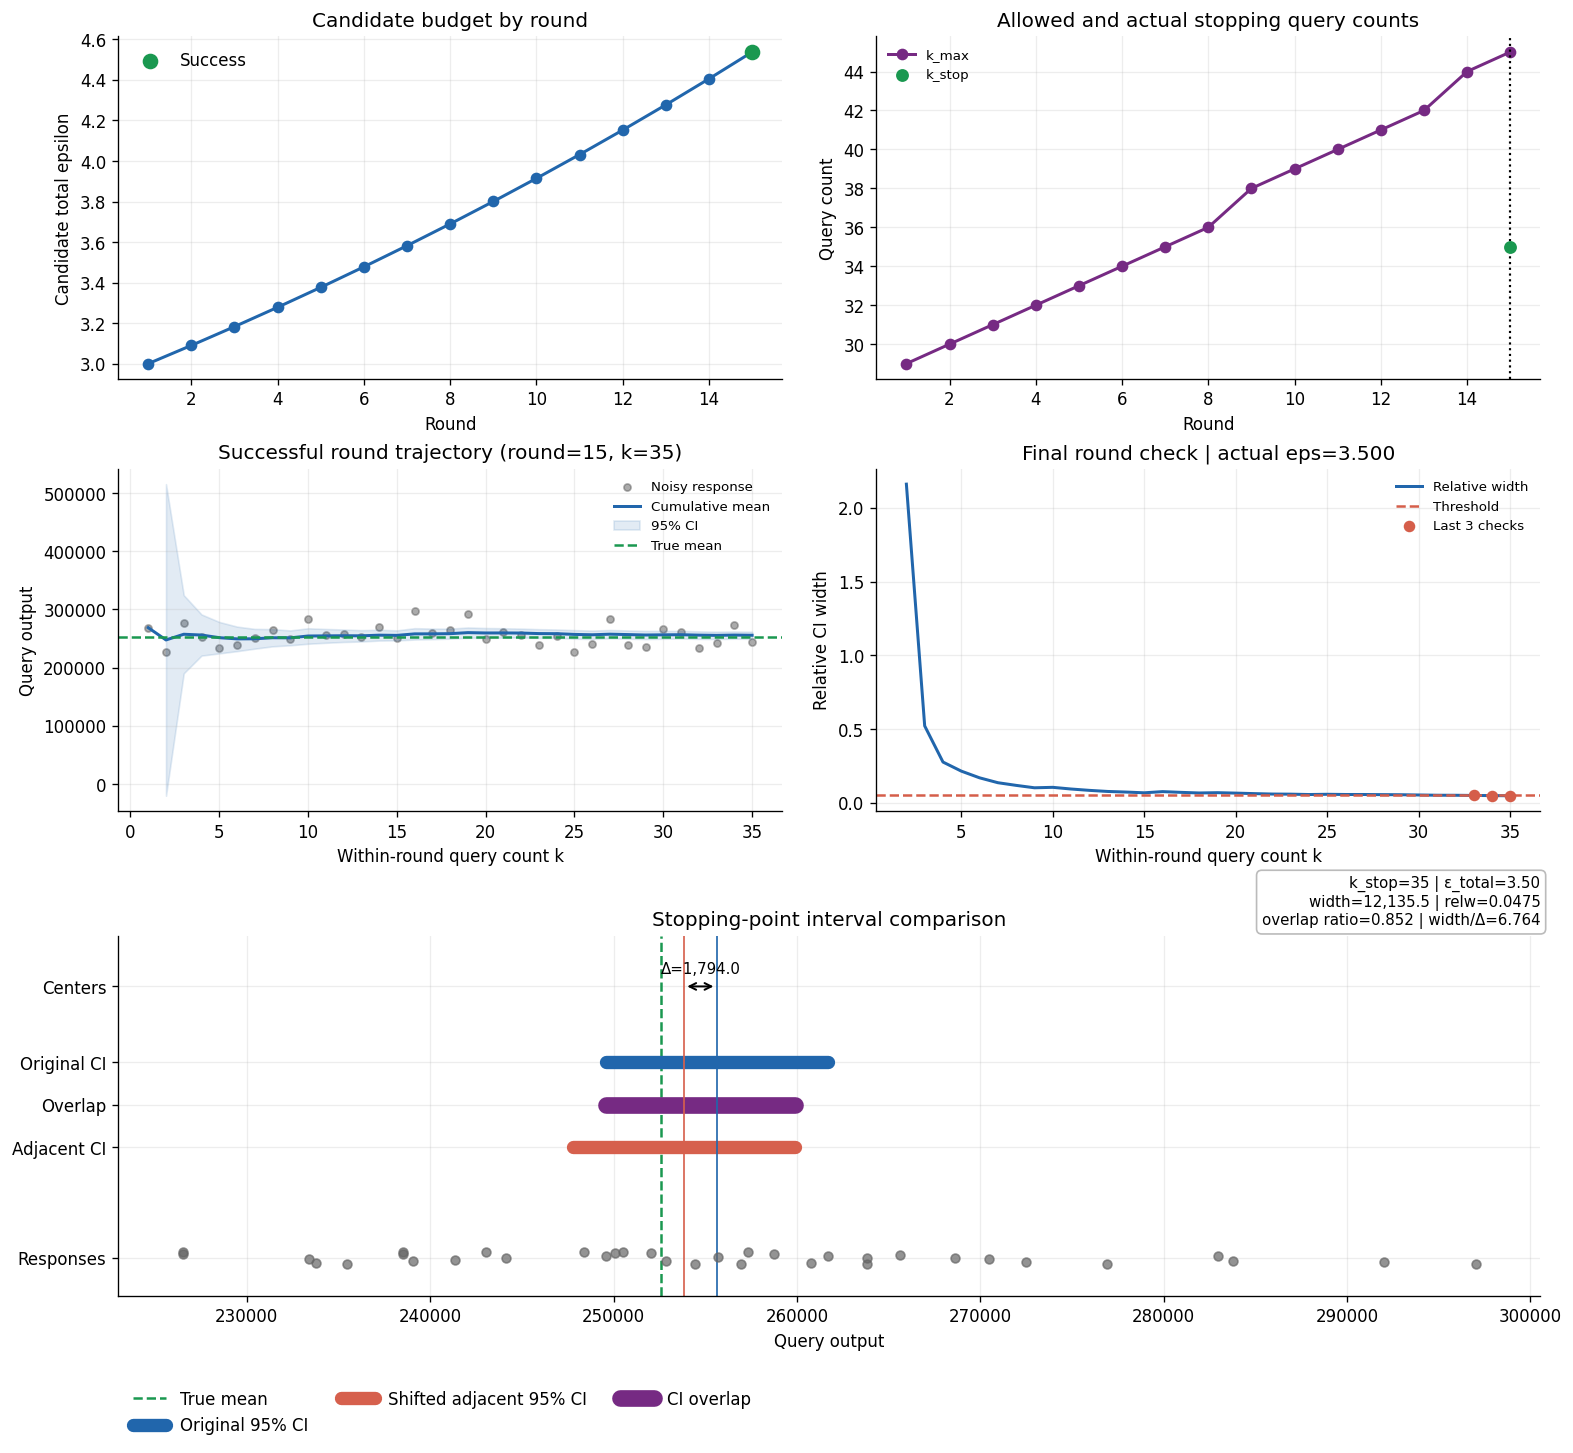

In [47]:
plot_inverse_live(inv_rounds, inv_trajectory, inv_final,
                  save=None);
                  # save=OUTPUT_DIR / "inverse_single_cardbase_2003.png");

### live 실험 반복

In [ ]:
def inverse_interactive_loop(n_reps=None, wait_sec=10,
                             base_dir=Path("/content/outputs/result_single"),
                             dataset="CardBase"):
    """반복 횟수를 받아 seed를 랜덤으로 정해 역산 live를 n_reps회 실행하고
    그림을 저장한 뒤 wait_sec초 대기. 반환: 전 시행 final의 DataFrame"""
    base_dir.mkdir(parents=True, exist_ok=True)
    if n_reps is None:
        n_reps = int(input("반복 횟수를 입력하세요: ").strip())

    results = []
    for i in range(n_reps):
        seed = random.randint(0, 10_000_000)
        inv_rounds, inv_trajectory, inv_final = run_inverse_live(
            DATA[dataset], eps=0.5, threshold=0.02,
            streak_required=5, initial_eps_total=5.0, step=1.10,
            max_rounds=100, maxq=500, seed=seed
        )

        save_path = base_dir / f"inv_live_{seed:04d}.png"
        fig = plot_inverse_live(inv_rounds, inv_trajectory, inv_final,
                                title=f"INVERSE single-run (seed={seed}, rep {i+1}/{n_reps})",
                                save=save_path)
        plt.show()
        time.sleep(wait_sec)
        plt.close(fig)

        results.append(inv_final)
        print(f"[{i+1}/{n_reps}] seed={seed} → 저장: {save_path}")

    return pd.DataFrame(results)

inverse_results = inverse_interactive_loop(wait_sec=12)

> KCI 반복 함수
* `run_kci_repeated()`

In [13]:
# @title
def run_kci_repeated(data, eps, threshold, streak_required, reps=10,
                     maxq=MAXQ, seed0=2026, alpha=ALPHA):
    """동일한 KCI 조건에서 seed만 바꾸어 반복한다."""
    finals, histories = [], []
    for rep in range(1, reps + 1):
        seed = int(seed0 + rep - 1)
        history, final = run_kci_live(data, eps, threshold, streak_required,
                                      maxq=maxq, seed=seed, alpha=alpha)
        final = dict(final)
        final.update({"rep": rep, "seed": seed})
        finals.append(final)
        h = history.copy()
        h.insert(0, "rep", rep)
        h.insert(1, "seed", seed)
        histories.append(h)
    final_results = pd.DataFrame(finals)
    trajectories = pd.concat(histories, ignore_index=True)
    summary = _summarize_repeated(final_results)
    summary["method"] = "KCI"
    summary["eps"] = eps
    summary["threshold"] = threshold
    summary["streak_required"] = streak_required
    return final_results, trajectories, summary

> INVERSE 반복 함수
* `run_inverse_repeated()`

In [14]:
# @title
def run_inverse_repeated(data, eps, threshold, streak_required,
                         initial_eps_total, step, reps=10, max_rounds=20,
                         maxq=MAXQ, seed0=2026, alpha=ALPHA):
    """동일한 역산 조건에서 seed만 바꾸어 반복한다.

    run_inverse_live의 실시간 streak 판정을 그대로 사용한다.
    즉, 각 라운드에서 k_max는 상한이고 streak을 먼저 달성하면
    k_stop에서 즉시 성공하며 actual_eps_total=eps*k_stop이다.
    """
    finals, round_frames, trajectory_frames = [], [], []
    for rep in range(1, reps + 1):
        seed = int(seed0 + rep - 1)
        rounds, trajectory, final = run_inverse_live(
            data, eps, threshold, streak_required,
            initial_eps_total=initial_eps_total, step=step,
            max_rounds=max_rounds, maxq=maxq, seed=seed, alpha=alpha
        )
        final = dict(final)
        final.update({"rep": rep, "seed": seed,
                      "final_k": final["k_stop"],
                      "final_eps_total": final["actual_eps_total"]})
        finals.append(final)
        r = rounds.copy(); r.insert(0, "rep", rep); r.insert(1, "seed", seed)
        t = trajectory.copy(); t.insert(0, "rep", rep); t.insert(1, "seed", seed)
        round_frames.append(r); trajectory_frames.append(t)
    final_results = pd.DataFrame(finals)
    final_results["eps_total"] = final_results["actual_eps_total"]
    round_results = pd.concat(round_frames, ignore_index=True)
    trajectories = pd.concat(trajectory_frames, ignore_index=True)
    summary = _summarize_repeated(final_results)
    summary["method"] = "INVERSE"
    summary["eps"] = eps
    summary["threshold"] = threshold
    summary["streak_required"] = streak_required
    summary["step"] = step
    return final_results, round_results, trajectories, summary

> 반복 실험을 위한 함수
* `plot_repeated_metrics()`: KCI와 역산 반복 결과의 최종 k·예산·CI 폭·coverage 비교
* `plot_repeated_trajectories()`: 반복별 상대폭 궤적과 중단점 분포를 표

In [15]:
# @title
def plot_repeated_metrics(kci_final, inverse_final, save=None):
    """KCI와 역산 반복 결과의 최종 k·예산·CI 폭·coverage 비교."""
    frames = []
    for method, df in [("KCI", kci_final), ("INVERSE", inverse_final)]:
        d = df.copy(); d["method"] = method
        frames.append(d)
    all_results = pd.concat(frames, ignore_index=True)
    metrics = [("k_stop", "Stopping query count"),
               ("eps_total", "Actual total epsilon"),
               ("ci_width", "Absolute CI width"),
               ("covered", "Coverage at stop")]
    fig, axes = plt.subplots(1, 4, figsize=(15, 4.3), constrained_layout=True)
    colors = {"KCI": "#2166AC", "INVERSE": "#D55E4A"}
    methods = ["KCI", "INVERSE"]
    for ax, (metric, label) in zip(axes, metrics):
        for x, method in enumerate(methods):
            v = all_results.loc[all_results["method"] == method, metric].astype(float).to_numpy()
            jitter = np.linspace(-.08, .08, len(v)) if len(v) > 1 else np.array([0.])
            q1, med, q3 = np.quantile(v, [0.25, .5, .75])
            ax.plot([x, x], [v.min(), v.max()], color=colors[method], lw=1.5)
            ax.plot([x, x], [q1, q3], color=colors[method], lw=9, solid_capstyle="round")
            ax.scatter(np.full(len(v), x) + jitter, v, color=colors[method], s=28,
                       edgecolor="white", linewidth=.5, zorder=3)
            ax.scatter([x], [med], facecolor="white", edgecolor="black", s=55, zorder=4)
            ax.scatter([x], [v.mean()], marker="D", facecolor="black", edgecolor="white", s=45, zorder=5)
        ax.set_xticks(range(2), methods)
        ax.set_title(label, fontweight="bold")
        ax.grid(axis="y", alpha=.25)
    axes[3].set_ylim(-.05, 1.05)
    fig.suptitle("KCI vs. inverse budget search under repeated identical conditions", fontsize=14, fontweight="bold")
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig


def plot_repeated_trajectories(trajectories, method, save=None):
    """반복별 상대폭 궤적과 중단점 분포를 표시한다."""
    fig, ax = plt.subplots(figsize=(11, 5.2))
    for rep, h in trajectories.groupby("rep"):
        if method == "INVERSE":
            h = h[h["round"] == h["round"].max()]
            x = h["k"]
        else:
            x = h["k"]
        ax.plot(x, h["relative_width"], color="#777777", alpha=.32, lw=1)
    if method == "KCI":
        stop = trajectories.groupby("rep").tail(1)
        ax.scatter(stop["k"], stop["relative_width"], color="#2166AC", s=35, label="KCI stop")
    else:
        stop = trajectories.groupby("rep").tail(1)
        ax.scatter(stop["k"], stop["relative_width"], color="#D55E4A", s=35, label="Inverse stop")
    first = trajectories.iloc[0]
    ax.axhline(first["threshold"], color="black", ls="--", lw=1.2, label="Threshold")
    ax.set_xlabel("Query count within displayed trajectory")
    ax.set_ylabel("Relative CI width")
    ax.set_title(f"{method}: repeated relative-width trajectories")
    ax.legend(frameon=False)
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

### 반복 실험

In [16]:
# === 동일한 조건에서 1000회 반복 실행 ===
kci_final, kci_trajectories, kci_summary = run_kci_repeated(
    DATA["CardBase"], 0.1, 0.03, 3, reps=1000,
    maxq=500, seed0=2025, alpha=ALPHA)

In [24]:
print(kci_summary["eps_total_mean"])

0    17.281
Name: eps_total_mean, dtype: float64


In [17]:
# === CardBase 데이터셋에서 역산 반복 실행 ===
inverse_final, inverse_rounds, inverse_trajectories, inverse_summary = run_inverse_repeated(
    DATA["CardBase"], 0.1, 0.03, 3,
    # 아래의 초기 엡실론과 배율은 데이터에 따라서 / 수렴 조건에 따라서 꼭 조정해야 함.
    6, 1.02, reps=1000, max_rounds=100,
    maxq=500, seed0=2025, alpha=ALPHA)

# === Bank 데이터셋에서 역산 반복 실행 ===
# inverse_final, inverse_rounds, inverse_trajectories, inverse_summary = run_inverse_repeated(
#     DATA["Bank"], 0.5, 0.01, 5,
#     # 아래의 초기 엡실론과 배율은 데이터에 따라서 꼭 조정해야 함.
#     2, 1.03, reps=50, max_rounds=50,
#     maxq=MAXQ, seed0=5, alpha=ALPHA)

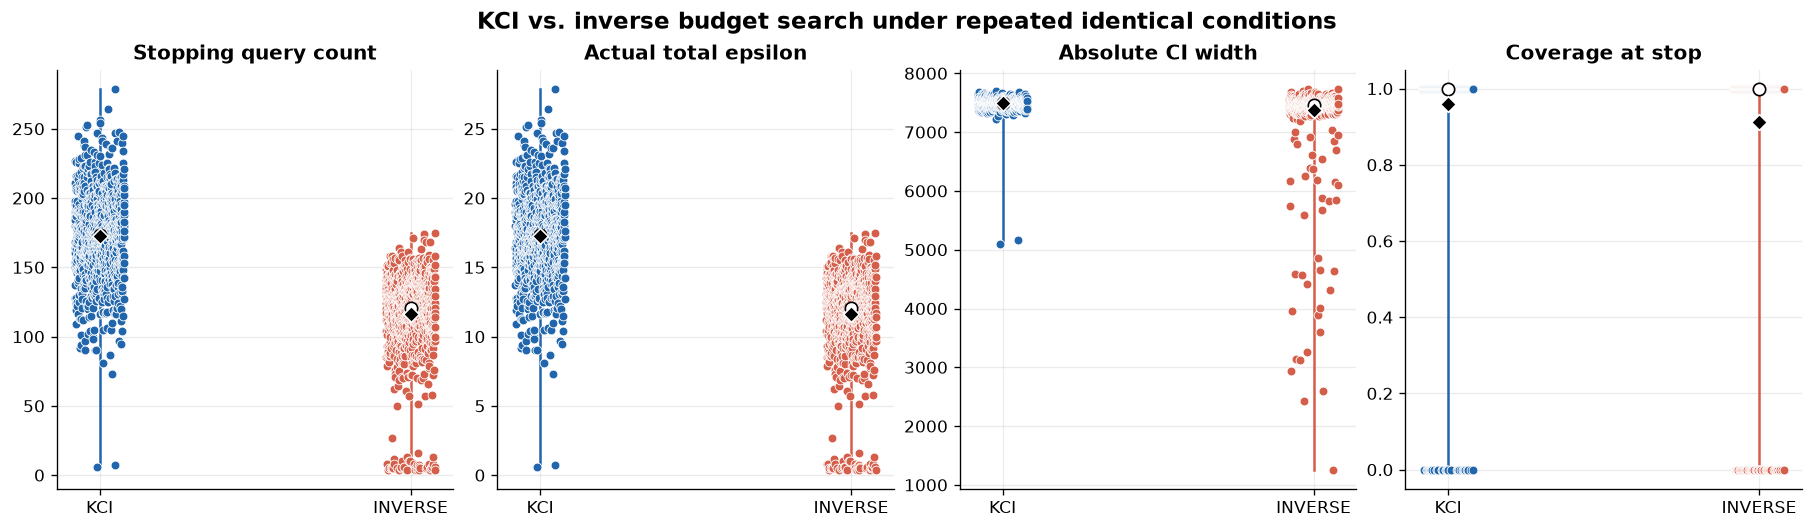

In [22]:
plot_repeated_metrics(kci_final, inverse_final, save=None);

> 시각화 함수 변경(total e)
* `plot_budget_pyramid()`

In [20]:
# @title
BLUE, RED, GREEN = "#2166AC", "#D55E4A", "#51D68B"


def _numeric(df, col):
    if col not in df.columns:
        raise KeyError(f"입력 DataFrame에 {col!r} 컬럼이 없습니다.")
    v = pd.to_numeric(df[col], errors="coerce").dropna().to_numpy(float)
    if len(v) == 0:
        raise ValueError(f"{col!r} 컬럼에 유효한 값이 없습니다.")
    return v


def plot_budget_pyramid(kci_final, inverse_final, col="eps_total", B_star=None,
                        value_labels=True, title=None, save=None,
                        label_fs=6.5, bar_h=.38):
    """반복 실험 두 방법의 총예산 분포를 퇴대비 히스토그램으로 비교한다.

    - 중앙 0축 기준 KCI는 왼쪽, INVERSE는 오른쪽 막대. x축 범위는 항상
      0 기준 좌우 대칭이라 중앙선이 figure 정중앙에 온다.
    - y축은 관측된 {col} 값의 합집합(오름차순) — 한쪽에만 나온 값도 표시된다.
    - 막대 길이 = 각 방법의 상대도수(행 합=1). 끝에 비율 숫자 병기(선택).
    - B_star를 넘으면 y=B_star 위치에 수평 기준선 + 오버슛 확률 주석(좌상단).
    입력: run_kci_repeated / run_inverse_repeated의 final_results DataFrame
    반환: (fig, ax)
    """
    v_kci = np.round(_numeric(kci_final, col), 6)
    v_inv = np.round(_numeric(inverse_final, col), 6)
    vals = np.union1d(np.unique(v_kci), np.unique(v_inv))
    pk = np.array([(v_kci == v).mean() for v in vals])
    pi = np.array([(v_inv == v).mean() for v in vals])

    fig, ax = plt.subplots(figsize=(4.9, 3.3), constrained_layout=True)
    ax.barh(vals, -pk, height=bar_h, color=BLUE, alpha=.85, label="KCI")
    ax.barh(vals, pi, height=bar_h, color=RED, alpha=.85, label="INVERSE")
    if value_labels:
        for v, p1, p2 in zip(vals, pk, pi):
            if p1 > 0:
                ax.text(-p1 - .015, v, f"{p1:.2f}", ha="right", va="center",
                        fontsize=label_fs, color=BLUE)
            if p2 > 0:
                ax.text(p2 + .015, v, f"{p2:.2f}", ha="left", va="center",
                        fontsize=label_fs, color=RED)
    ax.axvline(0, color="black", lw=.8)

    m = max(pk.max(), pi.max()) * 1.18 + .06
    ax.set_xlim(-m, m)          # 좌우 대칭 → 중앙선이 정중앙
    if B_star is not None:
        overshoot = float((v_kci > B_star).mean())
        ax.axhline(B_star, color=GREEN, ls="--", lw=1.2, zorder=1)
        ax.text(-m + m * .02, B_star + .06,
                f"INVERSE median = {B_star:.3g}",
                fontsize=7.5, color=GREEN, ha="left", va="bottom")
        # ax.text(-m + m * .02, B_star + .06,
        #         f"$B^{{*}}$ = {B_star:.3g}   P(KCI > $B^{{*}}$) = {overshoot:.3f}",
        #         fontsize=7.5, color=GREEN, ha="left", va="bottom")

    ax.set_yticks(vals, [f"{v:.3g}" for v in vals])
    ax.set_ylim(vals.min() - .5, vals.max() + .75)
    ax.set_xticks([])   # x축 눈금 삭제 - 확률은 막대 끝 숫자로만 표시
    ax.set_xlabel("Probability  (← KCI   |   INVERSE →)")
    ax.set_ylabel("Actual total epsilon")
    if title is None:
        title = (f"(a) Budget spend — KCI {v_kci.mean():.2f}±{v_kci.std():.2f}, "
                 f"INVERSE {v_inv.mean():.2f}±{v_inv.std():.2f}")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.legend(frameon=False, loc="upper right", fontsize=7)
    ax.spines["bottom"].set_visible(False)
    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig, ax

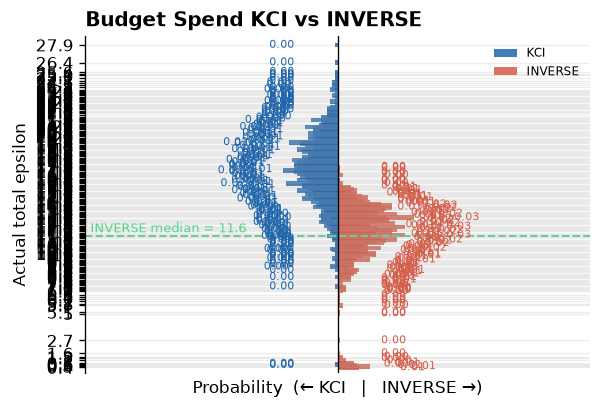

In [21]:
plot_budget_pyramid(kci_final, inverse_final, col="eps_total", B_star = float(inverse_final["eps_total"].mean()),
                    value_labels=True, title="Budget Spend KCI vs INVERSE", save=None);

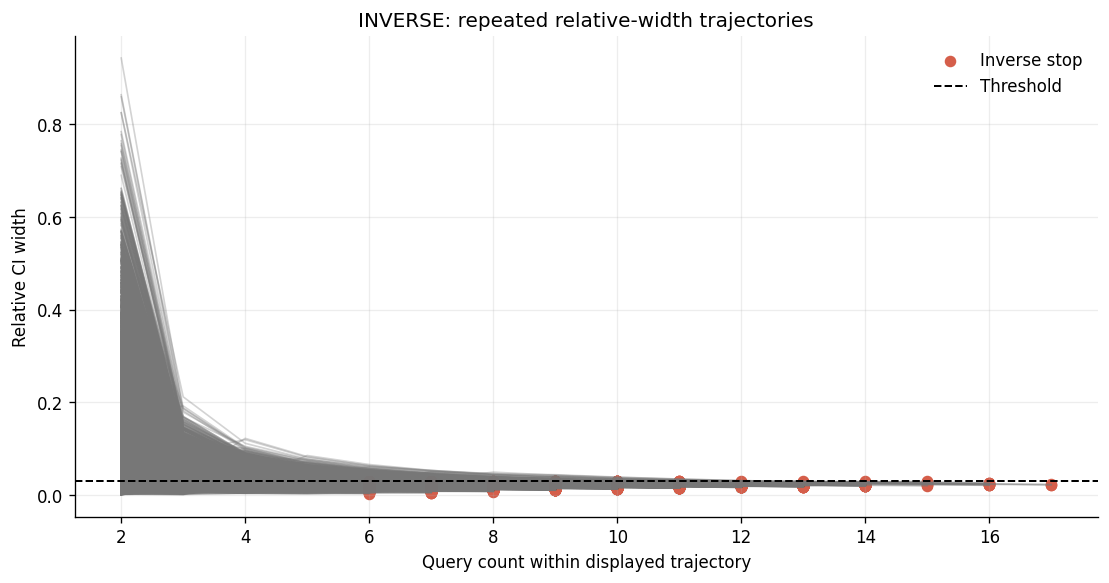

In [71]:
plot_repeated_trajectories(inverse_trajectories, "INVERSE", save=None);

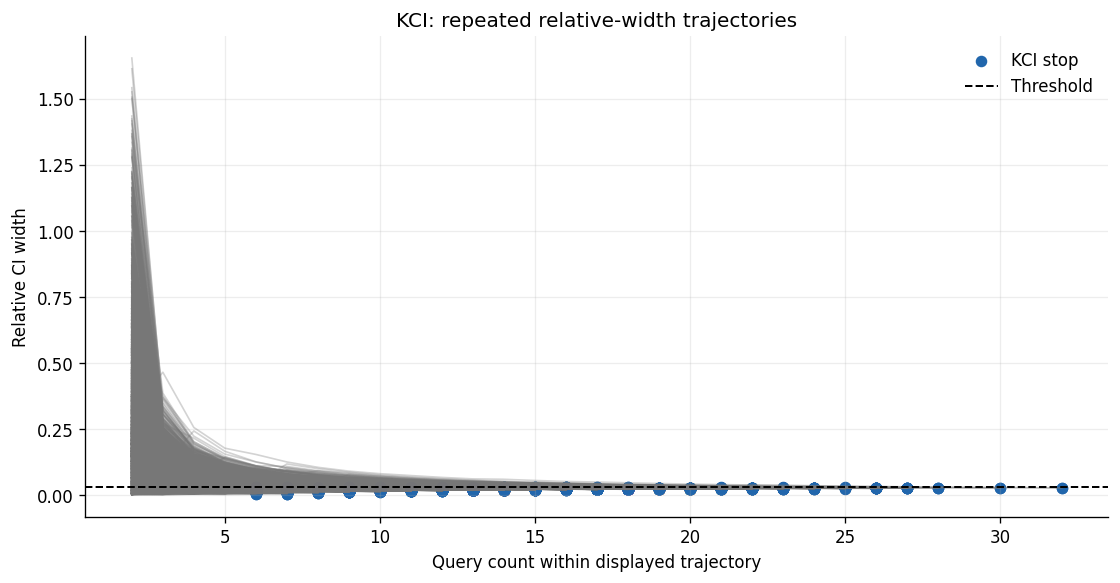

In [72]:
plot_repeated_trajectories(kci_trajectories, "KCI", save=None);